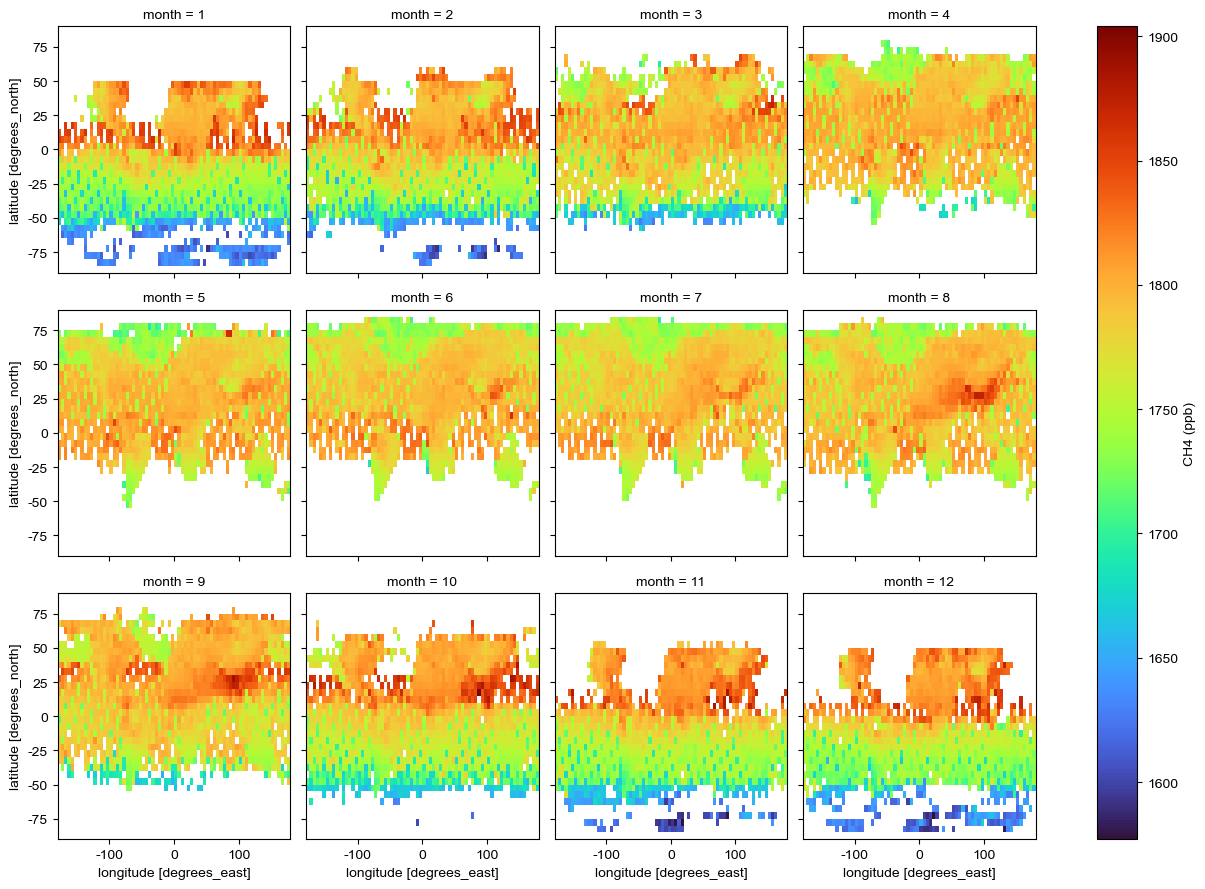

In [3]:
#第一题
#1.1 
import xarray as xr
import matplotlib.pyplot as plt

#读取文件和变量
ds = xr.open_dataset(
    '200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc',
    engine='netcdf4'
)
ch4 = ds['xch4'].sel(time=slice('2003-01', '2020-06'))

#剔除无效值、转换单位
ch4 = ch4.where(ch4 < 1e20) * 1e9

#计算月气候态
ch4_clim = ch4.groupby('time.month').mean(dim='time')

#画图
ch4_clim.plot(
    x='lon', y='lat', col='month', col_wrap=4,
    cmap='turbo', cbar_kwargs={'label': 'CH4 (ppb)'}
)
plt.show()

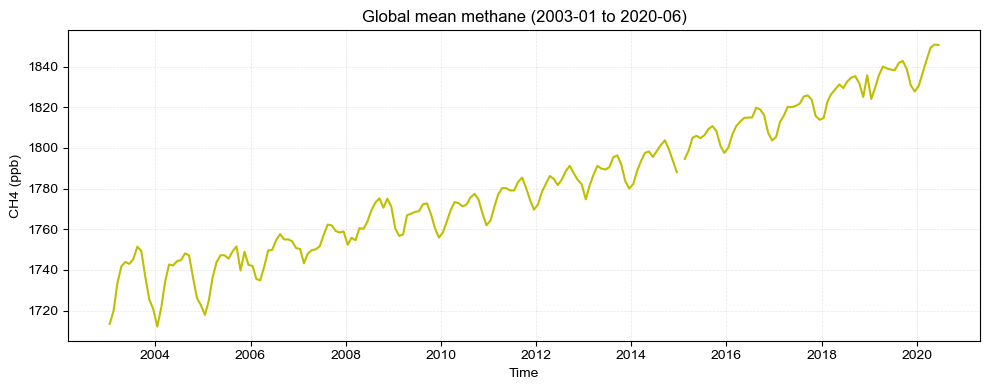

In [11]:
#1.2
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

ds = xr.open_dataset(
    '200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc',
    engine='netcdf4'
)
ch4 = ds['xch4'].sel(time=slice('2003-01', '2020-06'))

# 剔除缺失值并转为 ppb
ch4 = ch4.where(ch4 < 1e20) * 1e9

# 纬度余弦加权平均
weights = np.cos(np.deg2rad(ch4.lat))
global_ch4 = ch4.weighted(weights).mean(dim=['lat', 'lon'], skipna=True)

#画图
plt.figure(figsize=(10, 4))
global_ch4.plot(color='y')
plt.title('Global mean methane (2003-01 to 2020-06)')
plt.xlabel('Time')
plt.ylabel('CH4 (ppb)')
plt.grid(linestyle='--', linewidth=0.5, alpha=0.3)
plt.tight_layout()
plt.show()


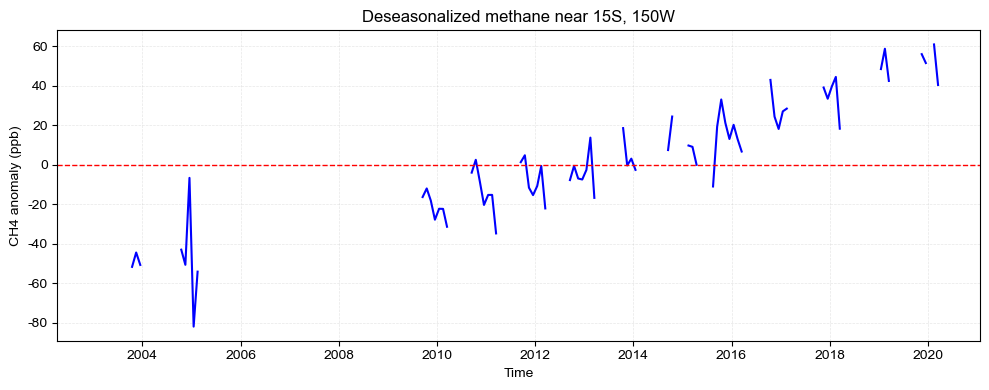

In [14]:
#1.3
import xarray as xr
import matplotlib.pyplot as plt

ds = xr.open_dataset(
    '200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc',
    engine='netcdf4'
)
ch4 = ds['xch4'].sel(time=slice('2003-01', '2020-06'))

ch4 = ch4.where(ch4 < 1e20) * 1e9

# 选择最近格点
lon = -150 if ds.lon.min() < 0 else 210
point_ch4 = ch4.sel(lat=-15, lon=lon, method='nearest')

# 去除季节循环
monthly = point_ch4.groupby('time.month')
ch4_anom = monthly - monthly.mean(dim='time')

plt.figure(figsize=(10, 4))
ch4_anom.plot(color='b')
plt.axhline(y=0, color='red', linestyle='--', linewidth=1)
plt.title('Deseasonalized methane near 15S, 150W')
plt.xlabel('Time')
plt.ylabel('CH4 anomaly (ppb)')
plt.grid(linestyle='--', linewidth=0.5, alpha=0.3)
plt.tight_layout()
plt.show()


In [20]:
#第二题
#2.1
import numpy as np
import xarray as xr

ds = xr.open_dataset('NOAA_NCDC_ERSST_v3b_SST.nc', engine='netcdf4')

# 提取 Niño 3.4 区域
sst = ds['sst'].sel(lat=slice(-5, 5), lon=slice(190, 240))

# 区域面积加权平均
weights = np.cos(np.deg2rad(sst.lat))
sst_mean = sst.weighted(weights).mean(dim=['lat', 'lon'], skipna=True)

# 月气候态与距平
sst_clim = sst_mean.groupby('time.month').mean(dim='time')
sst_anom = sst_mean.groupby('time.month') - sst_clim

print(sst_clim)
print(sst_anom)

<xarray.DataArray 'sst' (month: 12)> Size: 48B
array([26.56779 , 26.742273, 27.239603, 27.69374 , 27.795214, 27.597757,
       27.198917, 26.824203, 26.737827, 26.717142, 26.693287, 26.613092],
      dtype=float32)
Coordinates:
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
Attributes:
    pointwidth:          1.0
    valid_min:           -3.0
    valid_max:           45.0
    units:               degree_Celsius
    long_name:           Extended reconstructed sea surface temperature
    standard_name:       sea_surface_temperature
    iridl:hasSemantics:  iridl:SeaSurfaceTemperature
<xarray.DataArray 'sst' (time: 684)> Size: 3kB
array([-3.19671631e-01, -4.68568802e-01, -2.68173218e-01, -1.87025070e-01,
       -1.77633286e-01, -3.57751846e-01, -1.42024994e-01,  1.46160126e-02,
       -1.52326584e-01, -3.79961014e-01, -3.60948563e-01, -2.08705902e-01,
       -1.91469193e-01, -1.34254456e-01, -2.40343094e-01, -1.85152054e-01,
        5.19752502e-02,  2.39465714e-01, -7.02838898

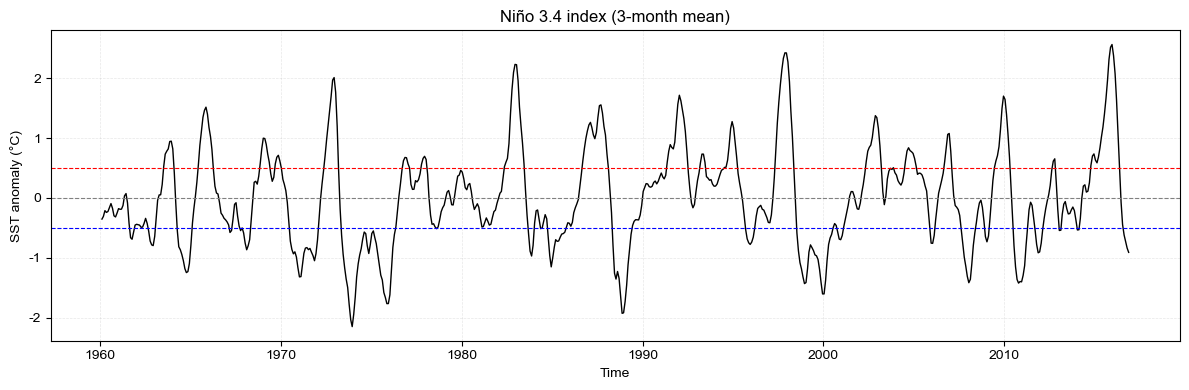

In [19]:
#2.2
#在2.1的基础上展开
# 三个月居中平均
nino34 = xr.DataArray(
    (sst_anom.values[:-2] + sst_anom.values[1:-1]
     + sst_anom.values[2:]) / 3,
    dims=['time'],
    coords={'time': sst_anom.time.values[1:-1]}
)

plt.figure(figsize=(12, 4))
nino34.plot(color='k', linewidth=1)
plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8)
plt.axhline(y=0.5, color='r', linestyle='--', linewidth=0.8)
plt.axhline(y=-0.5, color='b', linestyle='--', linewidth=0.8)
plt.title('Niño 3.4 index (3-month mean)')
plt.xlabel('Time')
plt.ylabel('SST anomaly (°C)')
plt.grid(linestyle='--', linewidth=0.5, alpha=0.3)
plt.tight_layout()
plt.show()

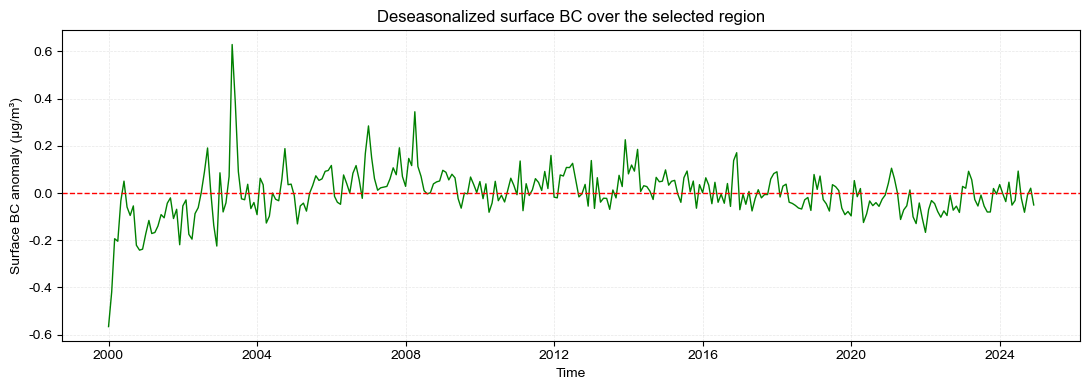

In [22]:
#第三题
#3.1
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

ds = xr.open_dataset(
    'MERRA2_BC_China_200001_202412.nc',
    engine='netcdf4'
)

# 按元数据筛选并转换单位
bc = ds['BCSMASS']
valid_min, valid_max = bc.attrs['valid_range']
fill_value = bc.attrs['fmissing_value']

bc = bc.where((bc >= valid_min) & (bc <= valid_max) & (bc != fill_value))
bc = bc * 1e9
bc.attrs['units'] = 'µg m-3'

# 区域面积加权平均
weights = np.cos(np.deg2rad(bc.lat))
bc_mean = bc.weighted(weights).mean(dim=['lat', 'lon'], skipna=True)

# 月气候态与距平
bc_clim = bc_mean.groupby('time.month').mean(dim='time')
bc_anom = bc_mean.groupby('time.month') - bc_clim

plt.figure(figsize=(11, 4))
bc_anom.plot(color='g', linewidth=1)
plt.axhline(y=0, color='r', linestyle='--', linewidth=1)
plt.title('Deseasonalized surface BC over the selected region')
plt.xlabel('Time')
plt.ylabel('Surface BC anomaly (µg/m³)')
plt.grid(linestyle='--', linewidth=0.5, alpha=0.3)
plt.tight_layout()
plt.show()

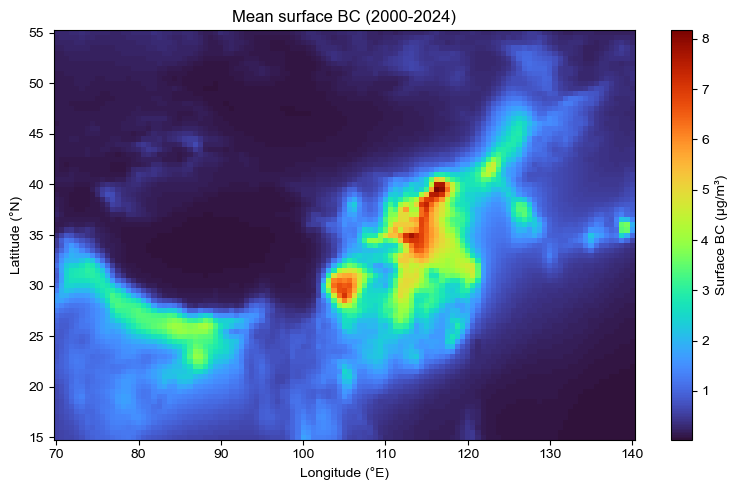

In [23]:
#3.2
#1.多年平均空间分布
bc_map = bc.mean(dim='time')

plt.figure(figsize=(8, 5))
bc_map.plot(
    x='lon', y='lat', cmap='turbo',
    cbar_kwargs={'label': 'Surface BC (µg/m³)'}
)
plt.title('Mean surface BC (2000-2024)')
plt.xlabel('Longitude (°E)')
plt.ylabel('Latitude (°N)')
plt.tight_layout()
plt.show()

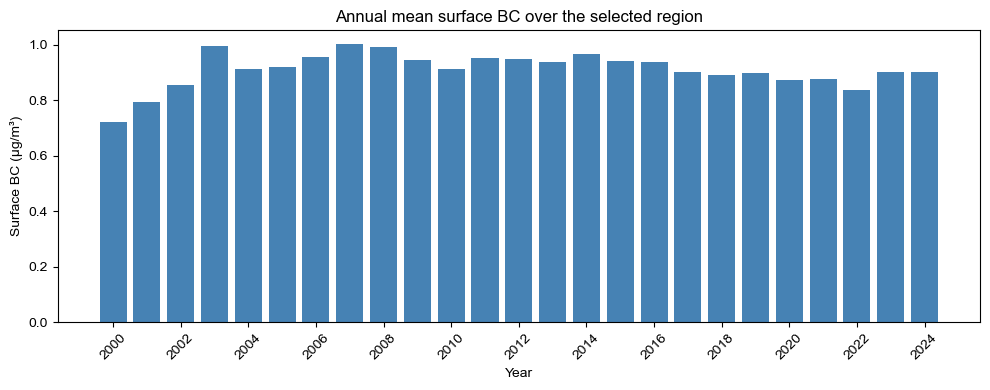

In [24]:
#2.年平均柱状图
bc_annual = bc_mean.groupby('time.year').mean(dim='time')

plt.figure(figsize=(10, 4))
plt.bar(bc_annual.year.values, bc_annual.values, color='steelblue')
plt.title('Annual mean surface BC over the selected region')
plt.xlabel('Year')
plt.ylabel('Surface BC (µg/m³)')
plt.xticks(bc_annual.year.values[::2], rotation=45)
plt.tight_layout()
plt.show()

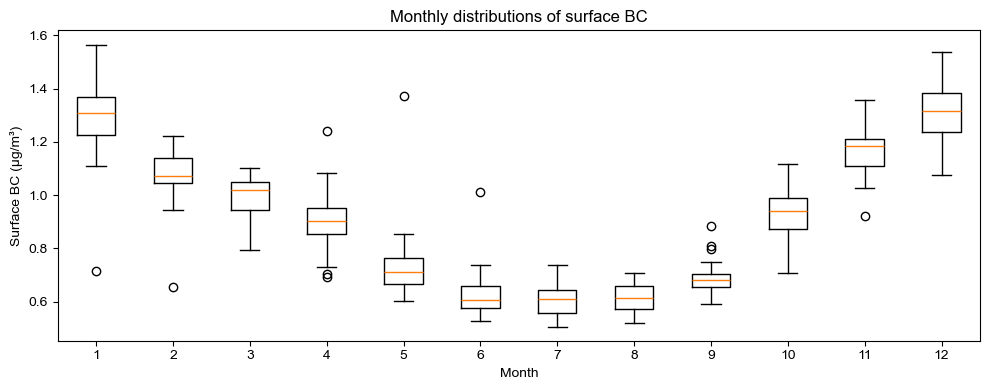

In [25]:
# 3.各月份箱线图
monthly_data = []
for month, group in bc_mean.groupby('time.month'):
    monthly_data.append(group.values)

plt.figure(figsize=(10, 4))
plt.boxplot(monthly_data)
plt.xticks(range(1, 13))
plt.title('Monthly distributions of surface BC')
plt.xlabel('Month')
plt.ylabel('Surface BC (µg/m³)')
plt.tight_layout()
plt.show()

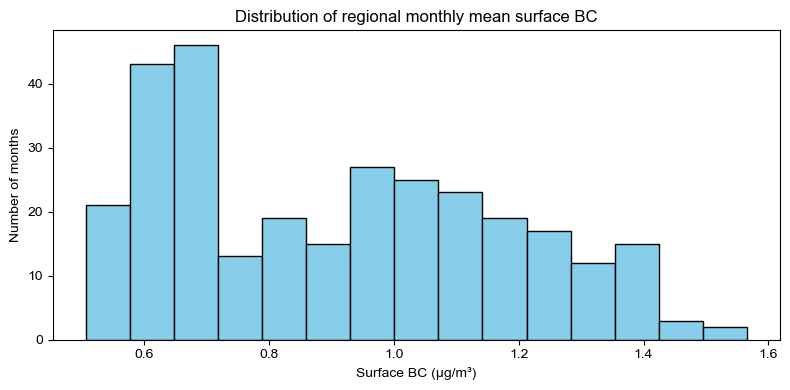

In [26]:
# 4.月平均浓度直方图
plt.figure(figsize=(8, 4))
plt.hist(bc_mean.values, bins=15, color='skyblue', edgecolor='k')
plt.title('Distribution of regional monthly mean surface BC')
plt.xlabel('Surface BC (µg/m³)')
plt.ylabel('Number of months')
plt.tight_layout()
plt.show()

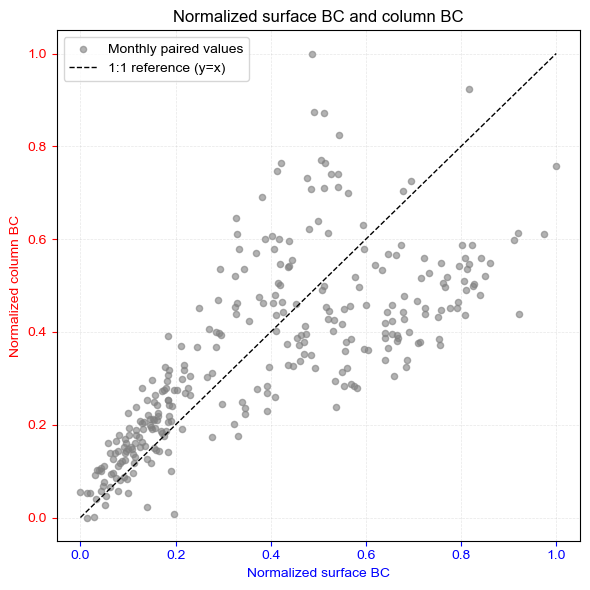

In [28]:
#5.地表浓度与柱质量的归一化散点图
bc_column = ds['BCCMASS'] * 1e6
bc_column_mean = bc_column.weighted(weights).mean(
    dim=['lat', 'lon'], skipna=True
)

# 分别归一化到 0—1
bc_norm = (bc_mean - bc_mean.min()) / (bc_mean.max() - bc_mean.min())
column_norm = (bc_column_mean - bc_column_mean.min()) / (bc_column_mean.max() - bc_column_mean.min())

plt.figure(figsize=(6, 6))
plt.scatter( bc_norm.values, column_norm.values,s=20, color='gray', alpha=0.6, label='Monthly paired values')

#1：1参考线
plt.plot(
    [0, 1], [0, 1], 'k--',
    linewidth=1, label='1:1 reference (y=x)'
)

plt.title('Normalized surface BC and column BC')
plt.xlabel('Normalized surface BC', color='b')
plt.ylabel('Normalized column BC', color='r')
plt.tick_params(axis='x', colors='b')
plt.tick_params(axis='y', colors='r')
plt.xlim(-0.05, 1.05)
plt.ylim(-0.05, 1.05)
plt.legend(loc='best')
plt.grid(linestyle='--', linewidth=0.5, alpha=0.3)
plt.tight_layout()
plt.show()